# 北京 PM2.5 污染变化趋势分析（2015—2025）

数据：`../data/` 目录下——北京 35 个国控站点逐小时空气质量数据（PM2.5/PM10/AQI）、ERA5 日度气象数据。

分析流程：读取数据 → 数据清洗 → 描述性统计 → 可视化 → 回归分析与气象校正。

## 1. 环境准备与数据读取

In [1]:
import math
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch
import statsmodels.api as sm

plt.rcParams['font.family'] = 'Noto Sans CJK SC'
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 110
plt.rcParams['savefig.dpi'] = 200
plt.rcParams['savefig.bbox'] = 'tight'

DATA = Path('../data')

# 原始站点-小时数据 + 气象数据
raw = pd.read_csv(DATA / 'raw_beijing_site_hour_2015_2025.csv.gz',
                 dtype={'date': str, 'hour': int, 'type': str})
STATION_COLS = [c for c in raw.columns if c.startswith('站点')]
raw[STATION_COLS] = raw[STATION_COLS].apply(pd.to_numeric, errors='coerce')

weather = pd.read_csv(DATA / 'weather_beijing_daily_2015_2025.csv')
weather['date'] = pd.to_datetime(weather['date'])

print(f'空气质量：{raw["date"].nunique()} 天 × {len(STATION_COLS)} 站点，指标 {raw["type"].unique().tolist()}')
print(f'气象数据：{len(weather)} 天')
raw.head(3)

空气质量：3999 天 × 35 站点，指标 ['PM2.5', 'PM10', 'AQI']
气象数据：4018 天


,date,hour,type,站点01,站点02,站点03,站点04,站点05,站点06,站点07,...,站点26,站点27,站点28,站点29,站点30,站点31,站点32,站点33,站点34,站点35
0,20150101,0,PM2.5,3.0,7.7,5.7,3.0,13.7,12.5,6.9,...,5.3,20.3,44.4,8.3,139.2,13.2,9.6,14.4,7.0,20.5
1,20150101,0,PM10,14.3,14.4,6.4,21.1,50.2,29.2,16.1,...,22.1,41.1,64.6,22.0,NaN,15.9,20.8,29.2,17.5,53.3
2,20150101,0,AQI,46.0,54.0,31.0,44.0,49.0,53.0,45.0,...,23.0,47.0,83.0,55.0,55.0,40.0,56.0,54.0,55.0,55.0


## 2. 数据清洗

按“**单元格 → 小时 → 日**”三级规则清洗：

- 单元格：剔除空值、负值、超物理上限值（PM2.5>1000、PM10>2000、AQI>500）；
- 小时：某整点有效站点数 ≥ 60%（21/35）才计算城市小时均值；
- 日：当日有效小时数 ≥ 18（75%）才计算日均值；源站缺失日不插值。

In [2]:
N_STATION, MIN_HOURS = 35, 18
LIMITS = {'PM2.5': 1000.0, 'PM10': 2000.0, 'AQI': 500.0}

daily_rows = []
for ymd, g in raw.groupby('date'):
    day_vals = {}
    for typ in ('PM2.5', 'PM10', 'AQI'):
        arr = g[g['type'] == typ].set_index('hour')[STATION_COLS]
        hourly = []
        for h in range(24):
            if h in arr.index:
                v = arr.loc[h]
                valid = v[(v >= 0) & (v <= LIMITS[typ])].dropna()
                if len(valid) >= math.ceil(0.6 * N_STATION):
                    hourly.append(valid.mean())
        if len(hourly) >= MIN_HOURS:
            day_vals[typ.lower().replace('.', '')] = round(float(np.mean(hourly)), 2)
    daily_rows.append({'date': f'{ymd[:4]}-{ymd[4:6]}-{ymd[6:]}', **day_vals})

air = pd.DataFrame(daily_rows)
air['date'] = pd.to_datetime(air['date'])

# 合并气象并构造派生变量
df = air.merge(weather, on='date', how='left').sort_values('date').reset_index(drop=True)
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df['ln_pm25'] = np.log(df['pm25'])
df['ratio'] = df['pm25'] / df['pm10']
df['heating'] = (((df['month'] == 11) & (df['date'].dt.day >= 15)) |
                 (df['month'] == 12) | (df['month'] <= 2) |
                 ((df['month'] == 3) & (df['date'].dt.day <= 15))).astype(int)
df['year_c'] = df['year'] - 2015

df[out_cols := ['date', 'pm25', 'pm10', 'aqi', 'temp', 'precip', 'wind', 'rh',
                'heating', 'ratio', 'ln_pm25', 'year', 'month']].to_csv(
    '../output/beijing_pm25_clean_daily.csv', index=False, encoding='utf-8-sig')

n_valid = int(df['pm25'].notna().sum())
print(f'有效日样本 {n_valid} 天（覆盖率 {n_valid/4018:.2%}）')
print(f'PM2.5 均值 {df["pm25"].mean():.1f}，中位数 {df["pm25"].median():.1f}，最大 {df["pm25"].max():.1f} μg/m³')
df.head(3)

有效日样本 3936 天（覆盖率 97.96%）
PM2.5 均值 46.1，中位数 31.5，最大 439.8 μg/m³


,date,pm25,pm10,aqi,temp,precip,wind,rh,year,month,ln_pm25,ratio,heating,year_c
0,2015-01-01,47.82,66.29,46.47,-3.4,0.0,11.7,21,2015,1,3.867444,0.721376,1,0
1,2015-01-02,67.41,89.56,90.45,-2.9,0.0,9.0,32,2015,1,4.210793,0.752680,1,0
2,2015-01-03,171.41,200.06,152.19,-2.0,0.0,9.3,44,2015,1,5.144058,0.856793,1,0


## 3. 描述性统计

In [3]:
vars_desc = {'pm25': 'PM2.5 (μg/m³)', 'pm10': 'PM10 (μg/m³)', 'aqi': 'AQI',
             'ratio': 'PM2.5/PM10', 'temp': '气温 (℃)', 'wind': '风速 (km/h)',
             'rh': '相对湿度 (%)', 'precip': '降水 (mm)'}
desc = pd.DataFrame({
    '变量': vars_desc.values(), '样本量': [int(df[k].notna().sum()) for k in vars_desc],
    '均值': [df[k].mean() for k in vars_desc], '标准差': [df[k].std() for k in vars_desc],
    '最小值': [df[k].min() for k in vars_desc], '中位数': [df[k].median() for k in vars_desc],
    'P95': [df[k].quantile(.95) for k in vars_desc], '最大值': [df[k].max() for k in vars_desc],
})
desc.round(2)

,变量,样本量,均值,标准差,最小值,中位数,P95,最大值
0,PM2.5 (μg/m³),3936,46.12,45.94,1.64,31.51,132.64,439.81
1,PM10 (μg/m³),3127,70.46,54.45,4.30,56.87,162.42,764.32
2,AQI,3924,74.86,52.72,11.62,60.43,178.42,459.06
3,PM2.5/PM10,3127,0.50,0.16,0.11,0.49,0.76,0.98
4,气温 (℃),3999,13.21,11.34,-14.50,14.30,28.50,34.00
5,风速 (km/h),3999,16.82,6.94,4.70,15.50,29.80,54.30
6,相对湿度 (%),3999,51.88,20.71,7.00,50.00,85.00,97.00
7,降水 (mm),3999,1.74,7.04,0.00,0.00,10.12,180.20


In [4]:
# 年度汇总：年均浓度、中位数、P95、重污染天数、达标率
yr = df.dropna(subset=['pm25']).groupby('year').agg(
    n=('pm25', 'size'), pm25_mean=('pm25', 'mean'), pm25_med=('pm25', 'median'),
    pm25_p95=('pm25', lambda s: np.percentile(s, 95)),
    heavy=('pm25', lambda s: int((s > 150).sum())),
).reset_index()
yr['attain'] = df.dropna(subset=['pm25']).groupby('year')['pm25'].apply(lambda s: (s <= 75).mean()).values * 100
yr.round(2)

,year,n,pm25_mean,pm25_med,pm25_p95,heavy,attain
0,2015,361,82.66,60.48,236.91,48,59.00
1,2016,358,73.75,58.70,200.10,38,62.29
2,2017,325,60.31,43.31,160.99,20,75.69
3,2018,361,52.59,43.97,136.94,13,79.22
4,2019,357,42.97,34.65,110.96,4,86.55
5,2020,361,38.55,29.76,100.60,8,90.03
6,2021,360,34.38,22.34,115.71,6,89.44
7,2022,365,30.38,21.97,89.64,2,92.05
8,2023,363,34.88,25.42,110.61,4,88.43
9,2024,364,31.38,25.16,80.63,1,93.96


## 4. 可视化

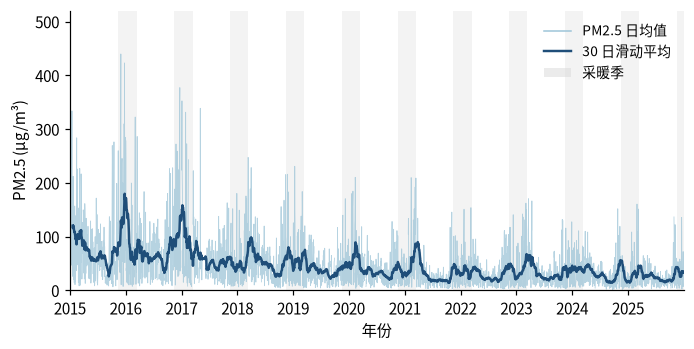

In [5]:
# 图 1 日度时间序列 + 30 日滑动平均
fig, ax = plt.subplots(figsize=(7.2, 3.3))
ax.plot(df['date'], df['pm25'], color='#9ec5d8', lw=0.55, alpha=0.75)
roll = df.set_index('date')['pm25'].rolling(30, min_periods=20).mean()
ax.plot(roll.index, roll.values, color='#1f4e79', lw=1.6)
for y in range(2015, 2026):
    ax.axvspan(pd.Timestamp(f'{y}-11-15'), pd.Timestamp(f'{y+1}-03-15'), color='#d9d9d9', alpha=0.30, lw=0)
ax.set_ylabel('PM2.5 (μg/m³)'); ax.set_xlabel('年份'); ax.set_ylim(0, 520)
ax.set_xlim(pd.Timestamp('2015-01-01'), pd.Timestamp('2025-12-31'))
ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.legend(loc='upper right', frameon=False, fontsize=9,
          handles=[plt.Line2D([], [], color='#9ec5d8', lw=1, label='PM2.5 日均值'),
                   plt.Line2D([], [], color='#1f4e79', lw=1.6, label='30 日滑动平均'),
                   Patch(facecolor='#d9d9d9', alpha=0.5, label='采暖季')])
ax.spines[['top', 'right']].set_visible(False)
plt.show()

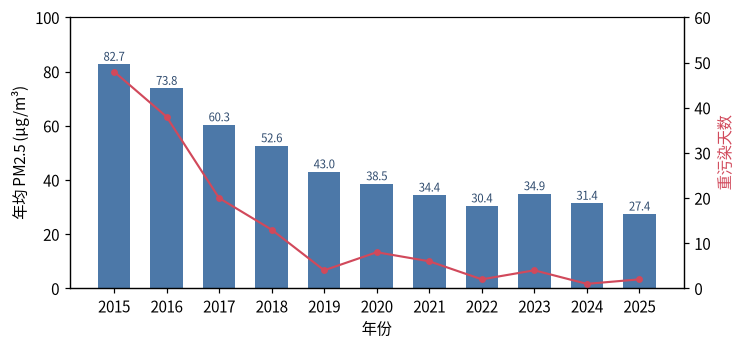

In [6]:
# 图 2 年均浓度 + 重污染天数
fig, ax = plt.subplots(figsize=(7.2, 3.2))
ax.bar(yr['year'], yr['pm25_mean'], color='#4c78a8', width=0.62)
for x, v in zip(yr['year'], yr['pm25_mean']):
    ax.text(x, v + 1.3, f'{v:.1f}', ha='center', fontsize=7.5, color='#2f4b6e')
ax.set_ylabel('年均 PM2.5 (μg/m³)'); ax.set_ylim(0, 100)
ax2 = ax.twinx()
ax2.plot(yr['year'], yr['heavy'], color='#d1495b', marker='o', ms=3.5, lw=1.4)
ax2.set_ylabel('重污染天数', color='#d1495b'); ax2.set_ylim(0, 60)
ax.set_xlabel('年份'); ax.set_xticks(yr['year'])
ax.spines[['top']].set_visible(False)
plt.show()

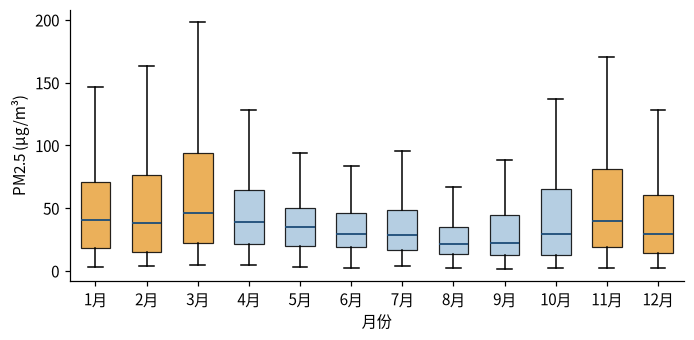

In [7]:
# 图 3 月度分布箱线图
fig, ax = plt.subplots(figsize=(7.2, 3.2))
data = [df.loc[df.month == m, 'pm25'].dropna().values for m in range(1, 13)]
bp = ax.boxplot(data, widths=0.58, patch_artist=True, showfliers=False,
                medianprops=dict(color='#1f4e79', lw=1.2))
for i, box in enumerate(bp['boxes']):
    box.set(facecolor='#e8a33d' if i in (10, 11, 0, 1, 2) else '#a8c6dd', alpha=0.85, lw=0.8)
ax.set_xticks(range(1, 13)); ax.set_xticklabels([f'{m}月' for m in range(1, 13)])
ax.set_ylabel('PM2.5 (μg/m³)'); ax.set_xlabel('月份')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

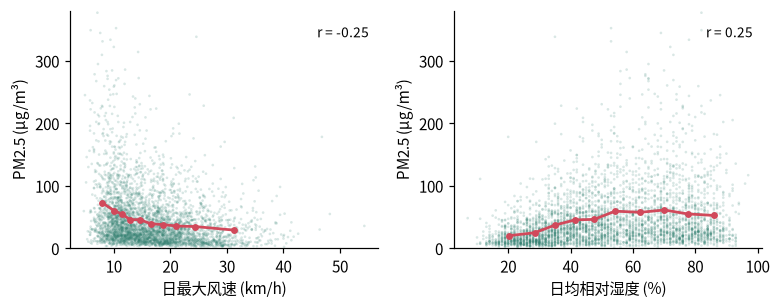

In [8]:
# 图 4 气象因子：风速与相对湿度
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.9))
for ax, var, lab in [(axes[0], 'wind', '日最大风速 (km/h)'), (axes[1], 'rh', '日均相对湿度 (%)')]:
    ax.scatter(df[var], df['pm25'], s=3, alpha=0.18, color='#2f7f6f', edgecolors='none')
    mm = df.groupby(pd.qcut(df[var], 10, duplicates='drop'), observed=True).agg(x=(var, 'mean'), y=('pm25', 'mean'))
    ax.plot(mm['x'], mm['y'], color='#d1495b', lw=1.8, marker='o', ms=3.5)
    ax.set_xlabel(lab); ax.set_ylabel('PM2.5 (μg/m³)'); ax.set_ylim(0, 380)
    r = df['pm25'].corr(df[var])
    ax.text(0.97, 0.94, f'r = {r:.2f}', transform=ax.transAxes, ha='right', va='top', fontsize=9)
    ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
plt.show()

## 5. 回归分析与气象校正

模型：ln(PM2.5) = α + β·年份趋势 + γ·气象变量 + 月份固定效应 + ε（Newey-West HAC 标准误，滞后 14 期）。

In [9]:
reg = df.dropna(subset=['ln_pm25', 'temp', 'wind', 'rh', 'precip']).copy()
mon = pd.get_dummies(reg['month'], prefix='m', drop_first=True, dtype=float)

X1 = sm.add_constant(pd.concat([reg[['year_c']], mon], axis=1))
m1 = sm.OLS(reg['ln_pm25'], X1).fit(cov_type='HAC', cov_kwds={'maxlags': 14})
X2 = sm.add_constant(pd.concat([reg[['year_c', 'wind', 'temp', 'rh', 'precip']], mon], axis=1))
m2 = sm.OLS(reg['ln_pm25'], X2).fit(cov_type='HAC', cov_kwds={'maxlags': 14})

def cell(m, k):
    star = '***' if m.pvalues[k] < .01 else '**' if m.pvalues[k] < .05 else '*' if m.pvalues[k] < .1 else ''
    return f'{m.params[k]:.4f}{star} ({m.bse[k]:.4f})'

pd.DataFrame({
    '变量': ['年份趋势', '风速', '气温', '相对湿度', '降水', '月份固定效应', '观测值', 'R²'],
    '模型(1)': [cell(m1, 'year_c'), '—', '—', '—', '—', '控制', f'{int(m1.nobs):,}', f'{m1.rsquared:.3f}'],
    '模型(2)': [cell(m2, 'year_c'), cell(m2, 'wind'), cell(m2, 'temp'),
                cell(m2, 'rh'), cell(m2, 'precip'), '控制', f'{int(m2.nobs):,}', f'{m2.rsquared:.3f}'],
})

,变量,模型(1),模型(2)
0,年份趋势,-0.1078*** (0.0065),-0.1117*** (0.0052)
1,风速,—,-0.0162*** (0.0024)
2,气温,—,0.0698*** (0.0044)
3,相对湿度,—,0.0273*** (0.0010)
4,降水,—,-0.0155*** (0.0033)
5,月份固定效应,控制,控制
6,观测值,"3,936","3,936"
7,R²,0.191,0.562


In [10]:
# 气象校正反事实：把每年气象条件固定在 2015 年水平；并对十年降幅作归因分解
full = reg[reg['year'].between(2015, 2025)]
w_ref = full[full.year == 2015][['wind', 'temp', 'rh', 'precip']].mean()
w_end = full[full.year == 2025][['wind', 'temp', 'rh', 'precip']].mean()

rows = []
for y in range(2015, 2026):
    sub = full[full.year == y]
    wy = sub[['wind', 'temp', 'rh', 'precip']].mean()
    weff = sum(m2.params[k] * (wy[k] - w_ref[k]) for k in w_ref.index)
    rows.append({'year': y, 'observed': sub['pm25'].mean(),
                 'adjusted': sub['pm25'].mean() / math.exp(weff)})
adj = pd.DataFrame(rows)

total = math.log(full[full.year == 2025]['pm25'].mean() / full[full.year == 2015]['pm25'].mean())
weather_part = sum(m2.params[k] * (w_end[k] - w_ref[k]) for k in w_ref.index)
trend_part = total - weather_part
print(f'十年实际降幅 {math.exp(total)-1:.1%}；趋势部分占 {trend_part/total:.1%}，气象部分占 {weather_part/total:.1%}')
adj.round(2)

十年实际降幅 -66.8%；趋势部分占 95.7%，气象部分占 4.3%


,year,observed,adjusted
0,2015,82.66,82.66
1,2016,73.75,76.37
2,2017,60.31,68.86
3,2018,52.59,66.60
4,2019,42.97,56.37
5,2020,38.55,45.06
6,2021,34.38,34.79
7,2022,30.38,36.22
8,2023,34.88,38.99
9,2024,31.38,31.31


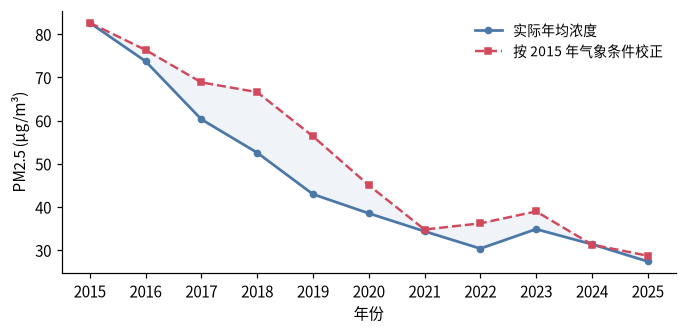

In [11]:
# 图 5 实际 vs 气象校正
fig, ax = plt.subplots(figsize=(7.2, 3.1))
ax.plot(adj['year'], adj['observed'], color='#4c78a8', marker='o', ms=4, lw=1.8, label='实际年均浓度')
ax.plot(adj['year'], adj['adjusted'], color='#d1495b', marker='s', ms=3.6, lw=1.6, ls='--',
        label='按 2015 年气象条件校正')
ax.fill_between(adj['year'], adj['adjusted'], adj['observed'], color='#4c78a8', alpha=0.08)
ax.set_xlabel('年份'); ax.set_ylabel('PM2.5 (μg/m³)'); ax.set_xticks(adj['year'])
ax.legend(frameon=False, fontsize=9)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

## 6. 主要结论

1. **浓度大幅下降**：年均 PM2.5 由 82.7 降至 27.4 μg/m³（-66.8%），重污染天数 48→2 天，达标率 59.0%→95.3%；
2. **冬高夏低**：1 月均值约为 8 月的 2.1 倍，采暖季比非采暖季高约 40%；
3. **气象因子显著**：风速、降水抑制浓度，相对湿度促进浓度（均 p<0.01），但单变量相关 |r|<0.26；
4. **改善主要来自趋势而非气象**：气象校正后趋势项对应年均下降约 10.6%，十年降幅中 95.7% 由趋势项解释、气象仅 4.3%。